# SaaS FP&A Financial Model — Full Walkthrough

This notebook builds a complete FP&A toolkit for a hypothetical early-stage SaaS
company, end to end: synthetic operating data, a linked three-statement model,
core SaaS KPIs, a bottoms-up Year 3 budget, budget-vs-actual variance analysis,
and a rolling 12-month cash flow forecast with scenario planning.

**Disclaimer:** every number in this notebook is synthetic, generated by
`src/saas_fpa/data_generator.py` from the driver assumptions in
`src/saas_fpa/assumptions.py`. It does not describe a real company. The
company profile, growth rate, and financial results are illustrative only,
built to be internally consistent and directionally realistic for an
early-stage, self-serve + inside-sales SMB SaaS business.

The commentary throughout is written the way an FP&A analyst would explain
these numbers to a hiring manager: not just *what* the model outputs, but
*why* each metric and technique matters to how a SaaS finance team actually
operates.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from saas_fpa.assumptions import OperatingAssumptions
from saas_fpa.budget_builder import build_year3_budget, budget_driver_summary, summarize_budget
from saas_fpa.cash_flow_forecast import build_rolling_forecast, scenario_summary
from saas_fpa.excel_report import build_workbook
from saas_fpa.saas_kpis import compute_kpis, kpi_snapshot
from saas_fpa.three_statement_model import build_balance_sheet, build_cash_flow_statement, build_income_statement, validate_tie_out
from saas_fpa.variance_analysis import build_variance_table, simulate_year3_actuals, variance_summary

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

a = OperatingAssumptions()
print(f"Modeling {a.n_months} months starting {a.start_date}")

Modeling 36 months starting 2023-01-01


## 1. Company profile and the operating engine

The model is driven by one dataclass, `OperatingAssumptions` — every downstream
module reads its numbers from here, nothing is hardcoded twice. The profile:
a seed-stage, SMB self-serve + inside-sales SaaS company starting around
$500K ARR with ~96 customers and 10 employees, financed by existing seed cash
plus a Series A in month 13.

`data_generator.py` simulates, month by month, the full MRR waterfall — new,
expansion, contraction, and churned MRR — tracked separately from new-logo
bookings so retention metrics are computed on the correct base (see Section 3).
Headcount is hired in waves tied to ARR milestones, not a flat headcount
schedule, which is how real SaaS companies actually plan hiring.

In [2]:
history, budget, state24 = build_year3_budget(a)
actual_y3, snapshots = simulate_year3_actuals(a, state24, capture_at={36})
combined_actual = pd.concat([history, actual_y3], ignore_index=True)

m1, m36 = combined_actual.iloc[0], combined_actual.iloc[-1]
print(f"Month 1:  MRR ${m1['mrr_ending']:,.0f} | ARR ${m1['arr_ending']:,.0f} | "
      f"{int(m1['customers_ending'])} customers | {int(m1['headcount_total'])} employees | cash ${m1['cash']:,.0f}")
print(f"Month 36: MRR ${m36['mrr_ending']:,.0f} | ARR ${m36['arr_ending']:,.0f} | "
      f"{int(m36['customers_ending'])} customers | {int(m36['headcount_total'])} employees | cash ${m36['cash']:,.0f}")
print(f"ARR growth multiple over 36 months: {m36['arr_ending'] / m1['arr_ending']:.2f}x")

Month 1:  MRR $42,597 | ARR $511,164 | 102 customers | 10 employees | cash $2,611,770
Month 36: MRR $205,001 | ARR $2,460,016 | 353 customers | 26 employees | cash $1,681,274
ARR growth multiple over 36 months: 4.81x


## 2. The linked three-statement model

A financial model is only useful to an FP&A team if it *ties out*: the balance
sheet balances every period, and the cash flow statement reconciles exactly to
the change in the cash balance. This isn't a formality — a model that doesn't
tie out has a broken assumption somewhere, and you can't trust anything it
outputs.

`three_statement_model.py` builds cash flow via the indirect method directly
from net income and the balance-sheet working-capital deltas, so the balance
sheet balances *by construction*, not by plugging a balancing figure. The
`validate_tie_out` check below confirms this holds in every one of the 36
months, to the cent.

In [3]:
tie_out = validate_tie_out(combined_actual)
print(tie_out)
assert tie_out["max_balance_sheet_diff"] < 0.01
assert tie_out["max_cash_flow_diff"] < 0.01
print("Three-statement model ties out in every month.")

{'months_checked': 36, 'max_balance_sheet_diff': 9.313225746154785e-10, 'max_cash_flow_diff': 0.0}
Three-statement model ties out in every month.


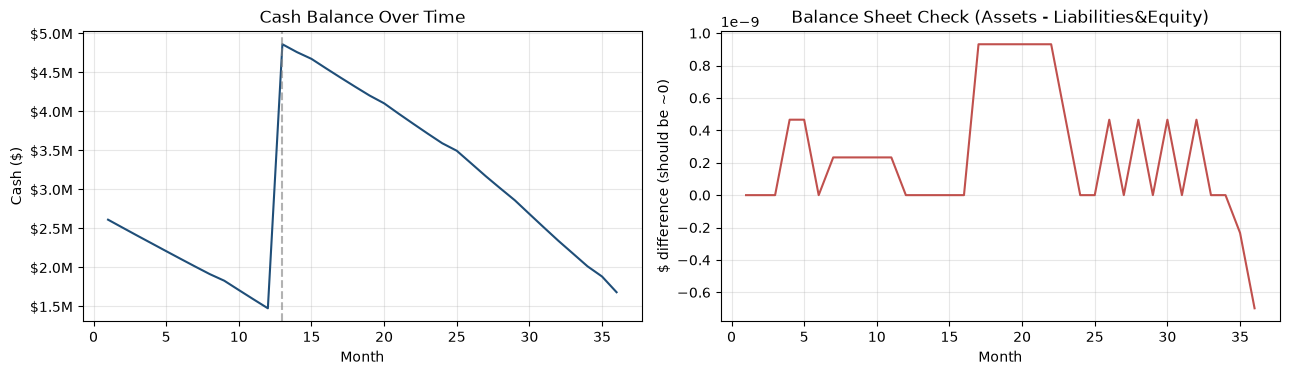

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(combined_actual["month"], combined_actual["cash"], color="#1F4E78")
axes[0].set_title("Cash Balance Over Time")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Cash ($)")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M"))
axes[0].axvline(13, color="gray", linestyle="--", alpha=0.6)
axes[0].annotate("Series A", xy=(13, combined_actual['cash'].max()*0.05), color="gray")

bs = build_balance_sheet(combined_actual)
axes[1].plot(bs["month"], bs["balance_check"], color="#C0504D")
axes[1].set_title("Balance Sheet Check (Assets - Liabilities&Equity)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("$ difference (should be ~0)")
plt.tight_layout()
plt.show()

## 3. Core SaaS KPIs — and why each one matters to FP&A

- **NRR (Net Revenue Retention)** tells you how much revenue a fixed cohort of
  existing customers generates a year later, including expansion — the single
  best signal of product-market fit and the ceiling on growth efficiency.
  Above 100% means the business would still grow even with *zero* new sales.
- **GRR (Gross Revenue Retention)** is the same base excluding expansion —
  it isolates how much revenue churn/contraction alone costs you, and it's
  capped at 100%.
- **CAC** (fully-loaded: all S&M spend, headcount and programs, divided by
  new customers) tells you what growth actually costs.
- **LTV:CAC** puts the lifetime value of a customer against that cost — the
  single most-cited unit economics ratio in SaaS, with 3:1+ considered healthy.
- **Rule of 40** (revenue growth % + profit margin %) is the classic SaaS
  framework for whether a company is balancing growth and profitability —
  most early-stage, growth-prioritizing companies fail it, which is itself
  useful context, not a red flag on its own.
- **Magic Number** measures sales efficiency: how much new revenue each
  dollar of S&M spend bought last quarter.
- **Burn rate & runway** are what keeps the company alive long enough to hit
  the metrics above — the most-watched numbers by any board at an
  early-stage company.

In [5]:
kpis = compute_kpis(combined_actual)
snap12 = kpi_snapshot(kpis, 12)
snap36 = kpi_snapshot(kpis, 36)
comparison = pd.DataFrame([snap12, snap36], index=["Month 12", "Month 36"]).T
comparison

,Month 12,Month 36
month,12.00,36.00
mrr,"78,784.20","205,001.31"
arr,"945,410.45","2,460,015.70"
customers,173.00,353.00
headcount,12.00,26.00
cash,"1,475,192.87","1,681,273.58"
nrr_ttm,0.93,1.05
grr_ttm,0.81,0.86
cac_trailing_3mo,"3,624.13","7,325.98"
ltv_to_cac,7.74,6.43


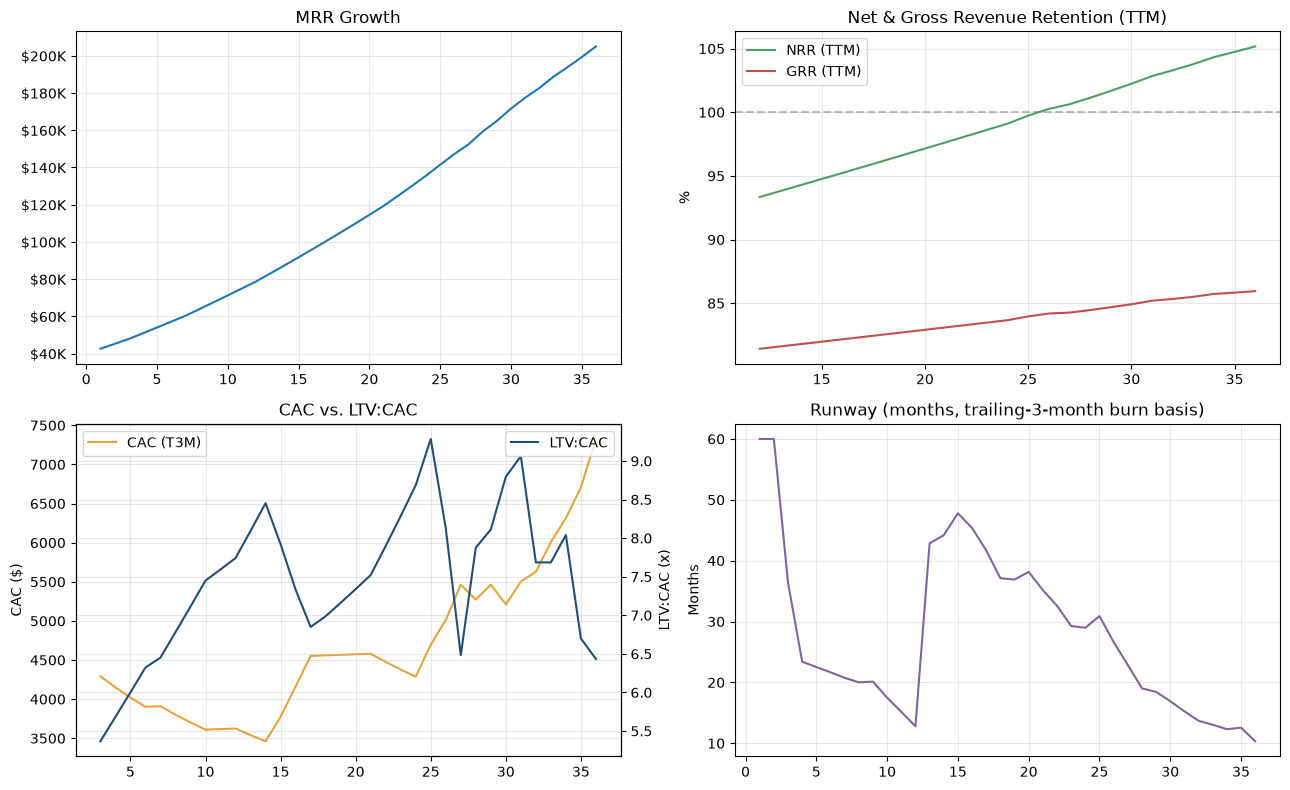

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].plot(kpis["month"], kpis["mrr_ending"], label="MRR")
axes[0, 0].set_title("MRR Growth")
axes[0, 0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e3:.0f}K"))

axes[0, 1].plot(kpis["month"], kpis["nrr_ttm"] * 100, label="NRR (TTM)", color="#4F9D69")
axes[0, 1].plot(kpis["month"], kpis["grr_ttm"] * 100, label="GRR (TTM)", color="#C0504D")
axes[0, 1].axhline(100, color="gray", linestyle="--", alpha=0.5)
axes[0, 1].set_title("Net & Gross Revenue Retention (TTM)")
axes[0, 1].set_ylabel("%")
axes[0, 1].legend()

axes[1, 0].plot(kpis["month"], kpis["cac_trailing_3mo"], label="CAC (T3M)", color="#E8A33D")
ax2 = axes[1, 0].twinx()
ax2.plot(kpis["month"], kpis["ltv_to_cac"], label="LTV:CAC", color="#1F4E78")
axes[1, 0].set_title("CAC vs. LTV:CAC")
axes[1, 0].set_ylabel("CAC ($)")
ax2.set_ylabel("LTV:CAC (x)")
axes[1, 0].legend(loc="upper left")
ax2.legend(loc="upper right")

axes[1, 1].plot(kpis["month"], kpis["runway_months"].clip(upper=60), color="#8064A2")
axes[1, 1].set_title("Runway (months, trailing-3-month burn basis)")
axes[1, 1].set_ylabel("Months")

plt.tight_layout()
plt.show()

Two things worth calling out for an interview conversation:

1. **NRR crosses 100% around month 30+** as churn improves and the expansion
   motion matures — a believable trajectory for a company moving from "prove
   retention works" to "retention is a growth lever."
2. **CAC rises over the period while LTV:CAC stays well above the 3:1
   benchmark** — acquisition got more expensive as easy top-of-funnel demand
   was exhausted, but improving retention kept unit economics healthy anyway.
   That's a nuanced, realistic story, not just "everything went up and to the
   right."

## 4. Building the Year 3 budget, bottoms-up

A credible budget isn't a straight line drawn from last year's number — it's
built from the same operating drivers that produced the actuals: the
headcount hiring plan (tied to ARR milestones), the churn/expansion schedule,
the new-bookings growth curve, and COGS assumptions. `budget_builder.py`
literally re-runs the same simulation engine forward from the real month-24
exit state using the Year 3 driver assumptions — which is what a real FP&A
team does when it builds next year's plan.

In [7]:
drivers = budget_driver_summary(a)
for k, v in drivers.items():
    print(f"{k}: {v}")
print()
totals = summarize_budget(budget)
for k, v in totals.items():
    print(f"{k}: {v:,.2f}" if isinstance(v, float) else f"{k}: {v}")

budget_months: (25, 36)
new_bookings_growth_rate_pct_range: (3.77, 2.2)
logo_churn_rate_pct_range: (1.06, 0.9)
expansion_rate_pct_range: (1.55, 1.8)
new_customer_acv_range: (5823.0, 6200.0)
cogs_pct_of_revenue_range: (21.57, 20.0)
headcount_plan_milestones: ((0, (2, 6, 2)), (750000, (2, 7, 3)), (1000000, (3, 8, 3)), (1300000, (3, 9, 4)), (1600000, (4, 11, 5)), (1900000, (4, 12, 6)), (2200000, (5, 14, 7)))
funding_events_in_year3: []

months: (25, 36)
total_revenue: 2,057,194.38
total_cogs: 426,457.37
total_opex: 3,808,794.29
total_opex_sm: 725,780.00
total_opex_rd: 2,110,414.29
total_opex_ga: 972,600.00
ending_arr: 2,427,981.77
ending_customers: 346
ending_headcount: 26
ending_cash: 1,649,504.28


## 5. Variance analysis: budget vs. actual

"Actuals" for Year 3 are generated by re-running the *same* simulation engine
with the drivers perturbed — modest random noise on every month, plus two
deliberate, named operating events layered on top (this mirrors how real
variance actually arises: a mix of everyday noise and specific decisions,
not just randomness):

- **A Q2 paid-acquisition push** (month 28): marketing deliberately overspent
  the S&M program budget to chase incremental pipeline.
- **A senior engineering hire fell through** (months 31-32): R&D ran behind
  its headcount plan for two months, which shows up as a timing-driven
  underspend, not a strategic decision.

For each of 10 P&L line items across all 12 months of Year 3 (120 line items
total), the variance table computes the dollar and percentage variance and
flags it as **material** only when it breaches *both* a percentage threshold
(10%) and a dollar threshold ($5,000) — avoiding false alarms from tiny bases
with big percentage swings. Each material item is also categorized by driver:
**volume** (units/customers), **price/rate** (per-unit economics), or
**timing** (a plan executed later or earlier than scheduled).

In [8]:
vt = build_variance_table(budget, actual_y3, a)
vsum = variance_summary(vt)
for k, v in vsum.items():
    print(f"{k}: {v:,.4f}" if isinstance(v, float) else f"{k}: {v}")

total_line_items_analyzed: 120
material_breaches: 16
material_breach_pct: 0.1333
total_revenue_budget: 2,057,194.3806
total_revenue_actual: 2,083,964.9986
total_revenue_variance: 26,770.6180
total_revenue_variance_pct: 0.0130
total_opex_budget: 3,808,794.2857
total_opex_actual: 3,800,781.6954
total_opex_variance: -8,012.5903
total_opex_variance_pct: -0.0021


In [9]:
material = vt[vt["material"]].copy()
print(f"{len(vt)} total line items analyzed, {len(material)} breached materiality "
      f"({len(material)/len(vt):.1%}).")
material.sort_values("variance", key=lambda s: s.abs(), ascending=False)[
    ["month", "line_item", "budget", "actual", "variance", "variance_pct", "driver_category", "note"]
].head(10)

120 total line items analyzed, 16 breached materiality (13.3%).


,month,line_item,budget,actual,variance,variance_pct,driver_category,note
98,34,ebitda,"-213,420.67","-159,334.10","54,086.57",0.25,derived,roll-up of underlying line items
99,34,net_income,"-208,449.64","-154,438.43","54,011.22",0.26,derived,roll-up of underlying line items
97,34,total_opex,"365,779.43","313,908.47","-51,870.95",-0.14,derived,roll-up of underlying line items
95,34,opex_rd,"202,542.86","175,244.76","-27,298.10",-0.13,timing,headcount behind plan (12 vs 14 budgeted heads...
48,29,ebitda,"-162,027.32","-185,959.97","-23,932.65",-0.15,derived,roll-up of underlying line items
49,29,net_income,"-154,019.92","-177,930.00","-23,910.08",-0.16,derived,roll-up of underlying line items
31,28,new_bookings_arr,"59,257.14","76,607.06","17,349.92",0.29,volume,new-logo count beat plan (13 vs 10 planned)
94,34,opex_sm,"68,536.57","54,930.36","-13,606.22",-0.20,timing,headcount behind plan (4 vs 5 budgeted heads) ...
46,29,opex_ga,"71,700.00","82,833.96","11,133.96",0.16,timing,headcount ahead of plan (6 vs 5 budgeted heads...
96,34,opex_ga,"94,700.00","83,733.36","-10,966.64",-0.12,timing,headcount behind plan (6 vs 7 budgeted heads) ...


**The concrete story this tells:** in month 28, S&M overspent budget by
~12% funding a deliberate paid-acquisition push — and new bookings ARR beat
budget by ~29% that same month, a volume-driven beat. That's the kind of
variance a good FP&A analyst *investigates rather than just flags*: the
overspend converted into real pipeline, so the story in a board deck isn't
"S&M is over budget," it's "S&M invested ahead of plan and it paid off."

By contrast, month 34's favorable opex variance across S&M, R&D, and G&A
(headcount running behind the hiring plan) isn't good news — it's a
timing-driven miss on the hiring plan that will need to be caught up, and a
good variance report calls that out explicitly rather than just booking the
"beat" as a win.

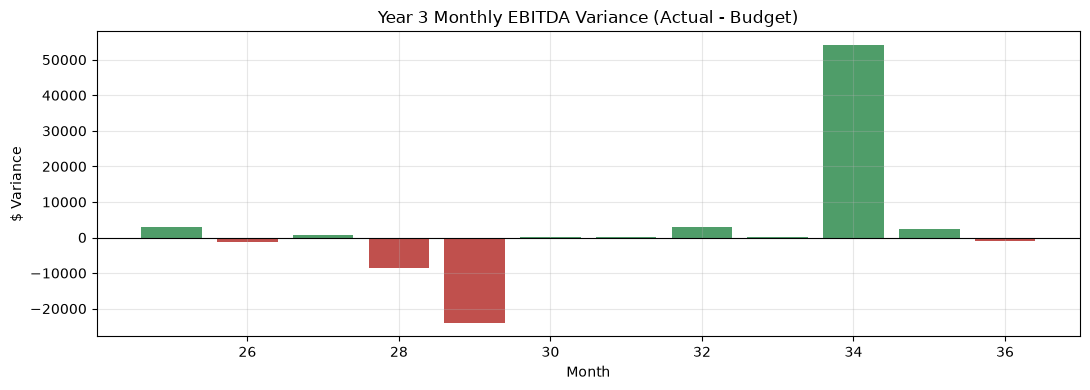

In [10]:
fig, ax = plt.subplots(figsize=(11, 4))
by_month = vt[vt["line_item"] == "ebitda"].sort_values("month")
colors = ["#4F9D69" if v >= 0 else "#C0504D" for v in by_month["variance"]]
ax.bar(by_month["month"], by_month["variance"], color=colors)
ax.set_title("Year 3 Monthly EBITDA Variance (Actual - Budget)")
ax.set_xlabel("Month")
ax.set_ylabel("$ Variance")
ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

## 6. Rolling 12-month cash flow forecast, with scenarios

A cash forecast is only as good as its last refresh — "rolling" means a new
12-month projection is branched every time new actuals land, from the real
state at that point (not from the original budget). Below, two forecast
vintages are shown: one branched at month 24 (before Year 3 actuals existed)
and one branched at month 36 (using the full realized Year 3 actuals).

Each vintage runs three scenarios by flexing two levers — new-bookings growth
and logo churn — rather than hand-waving a range:

- **Base**: assumptions as planned
- **Upside**: growth x1.25, churn x0.85
- **Downside**: growth x0.70, churn x1.30

In [11]:
rolling = build_rolling_forecast(a, {24: state24, 36: snapshots[36]}, n_months=12)
for as_of_month, fdf in rolling.items():
    starting_cash = float(fdf["cash"].iloc[0])
    print(f"--- Forecast as of month {as_of_month} ---")
    display(scenario_summary(fdf, starting_cash=starting_cash))

--- Forecast as of month 24 ---


,scenario,ending_arr,ending_cash,min_cash,min_cash_month,avg_net_burn,runway_months_from_as_of,cash_runs_out
0,downside,"2,113,938.61","1,677,094.88","1,677,094.88",36,"157,085.37",22.22,False
1,base,"2,427,981.77","1,649,504.28","1,649,504.28",36,"159,384.58",21.90,False
2,upside,"2,694,559.94","1,602,197.52","1,602,197.52",36,"163,326.81",21.37,False


--- Forecast as of month 36 ---


,scenario,ending_arr,ending_cash,min_cash,min_cash_month,avg_net_burn,runway_months_from_as_of,cash_runs_out
0,downside,"2,969,596.19","-534,867.77","-534,867.77",48,"182,178.45",8.11,True
1,base,"3,188,742.06","-456,045.34","-456,045.34",48,"175,609.91",8.42,True
2,upside,"3,362,406.03","-395,663.86","-395,663.86",48,"170,578.12",8.66,True


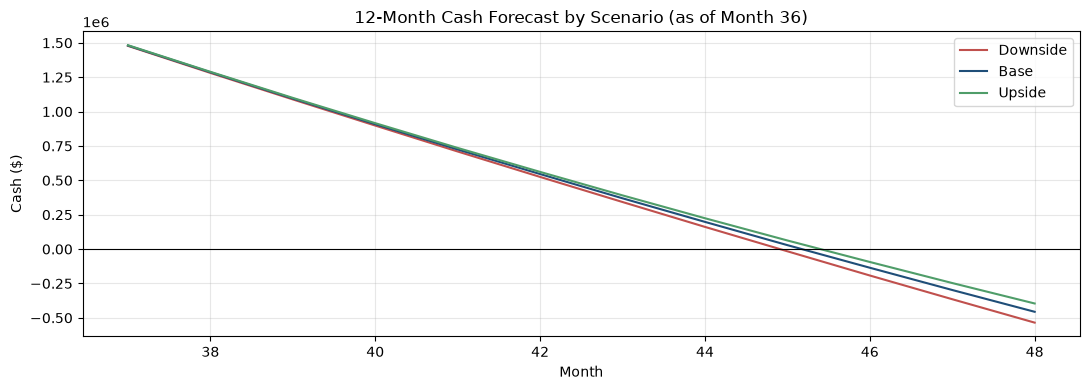

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
fdf36 = rolling[36]
colors = {"downside": "#C0504D", "base": "#1F4E78", "upside": "#4F9D69"}
for scenario in ("downside", "base", "upside"):
    sub = fdf36[fdf36["scenario"] == scenario].sort_values("month")
    ax.plot(sub["month"], sub["cash"], label=scenario.capitalize(), color=colors[scenario])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("12-Month Cash Forecast by Scenario (as of Month 36)")
ax.set_xlabel("Month")
ax.set_ylabel("Cash ($)")
ax.legend()
plt.tight_layout()
plt.show()

**The headline finding:** as of month 36, all three scenarios — even
upside — show cash running out within roughly 8-9 months without additional
financing. That's the real value of scenario planning: it shows growth alone
doesn't fix the runway problem here, because burn scales with the same
ARR-triggered hiring plan that drives growth. The actionable conclusion for a
board conversation is "we need to either raise, or slow hiring relative to
ARR milestones" — not "let's hope for the upside case."

## 7. The Excel deliverable

`excel_report.py` builds a management-reporting workbook with **formula-driven
summary tables** (XLOOKUP against the raw data tabs, live arithmetic for
variance $ and %) and **native Excel charts** — not static pasted values. See
the project README for the full list of tabs and a note on why native
PivotTable *objects* aren't used (they can't be reliably created from
scratch by Python).

In [13]:
result = build_workbook(a, kpis, budget, vt, rolling, "../output/saas_fpa_model.xlsx")
result

{'tabs': 8,
 'tab_names': ['Assumptions',
  'Data_Actuals',
  'Data_BudgetY3',
  'PL_Actual_vs_Budget',
  'KPI_Dashboard',
  'Variance_Waterfall',
  'Variance_Detail',
  'Cash_Flow_Forecast'],
 'native_charts': 6}

## Summary

This model demonstrates the core FP&A toolkit end to end: a three-statement
model that ties out, correctly-defined SaaS KPIs, a bottoms-up budget built
from operating drivers, variance analysis that categorizes *why* a number
missed rather than just flagging that it did, and a rolling cash forecast
with real scenario planning. Every number here is synthetic — built to be
internally consistent and realistic, not to describe an actual company.